# Ecoverse 813 — 01 · Hyperspectral calibration on Gulf analogue scenes
**Question:** which soil and plant signals that matter for plant survival in Bahrain *need* a hyperspectral sensor (Tanager today,
Satellite 813 tomorrow), and which can Sentinel-2 already approximate?

**Data:** open Planet Tanager surface-reflectance scenes (426 bands, 380–2500 nm, ~30 m) over a **coastal sabkha on Abu Dhabi's Al Dhafra coast**
and **Riyadh** — the closest open-archive analogues to Bahrain's saline coast and arid city. `scripts/fetch_data.py` downloaded each
HDF5, removed water-vapour and noisy edge bands, and saved a compact subset (pixel sample with Sentinel-2-simulated bands, narrow-band
features and 20 principal components of the full spectrum, plus thinned feature maps) to `data/sample_input/tanager_gulf/`.

**Method:** continuum-removed absorption depths (gypsum 1750 nm, clay 2200 nm, carbonate 2340 nm, canopy water 1200 nm) and red-edge
position; Sentinel-2 simulated with Gaussian spectral response functions; spatially-blocked 5-fold cross-validation (32 × 32 px blocks)
so near-identical neighbouring pixels never sit on both sides of a split.

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)   # all-NaN medians at scene edges

from ecoverse import config, io, fingerprint, plants, recommend, uncertainty, hyperspectral, viz, report
np.random.seed(config.RANDOM_SEED)
pd.set_option("display.width", 160, "display.max_columns", 20, "display.precision", 3)
print("Repository root:", ROOT.name)
print("Results folder :", config.RESULTS_DIR.relative_to(ROOT) if config.RESULTS_DIR.is_relative_to(ROOT) else config.RESULTS_DIR)

Repository root: ecoverse-final
Results folder : results


In [2]:
tdf, tmeta, tmaps = hyperspectral.load_tanager_tables()
pd.DataFrame(tmeta).T[["label", "datetime", "n_bands_total", "n_bands_used", "valid_pct", "land_pct", "n_sampled_pixels"]]

,label,datetime,n_bands_total,n_bands_used,valid_pct,land_pct,n_sampled_pixels
20250511_074311_00_4001,"Al Dhafra coast, Abu Dhabi (coastal sabkha)",2025-05-11T07:43:11Z,426,361,38.63,1.152,7416
20250515_080954_16_4001,"Riyadh (arid city, irrigated parks)",2025-05-15T08:09:54.165094Z,426,361,18.897,18.888,12000
20250608_074757_58_4001,Rub al Khali margin (desert sand),2025-06-08T07:47:57.582000Z,426,361,34.13,34.13,12000


## 1 · Feature maps that only hyperspectral resolves

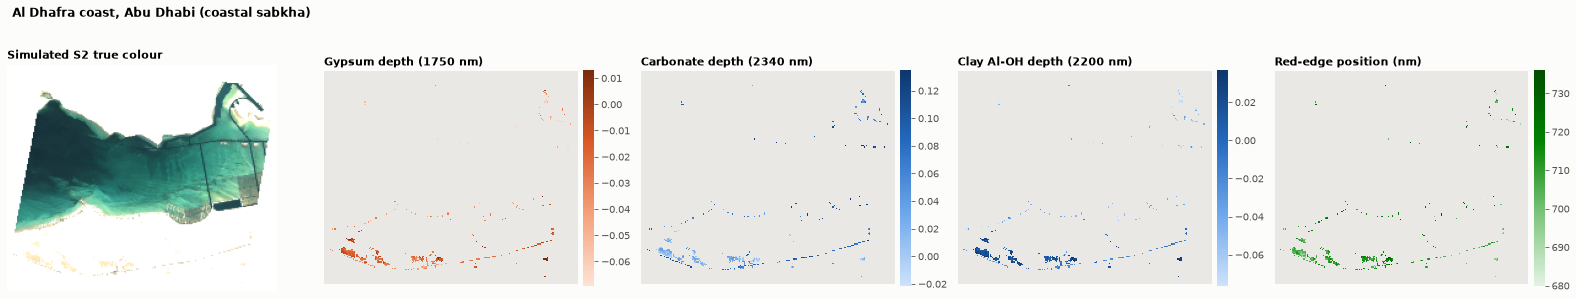

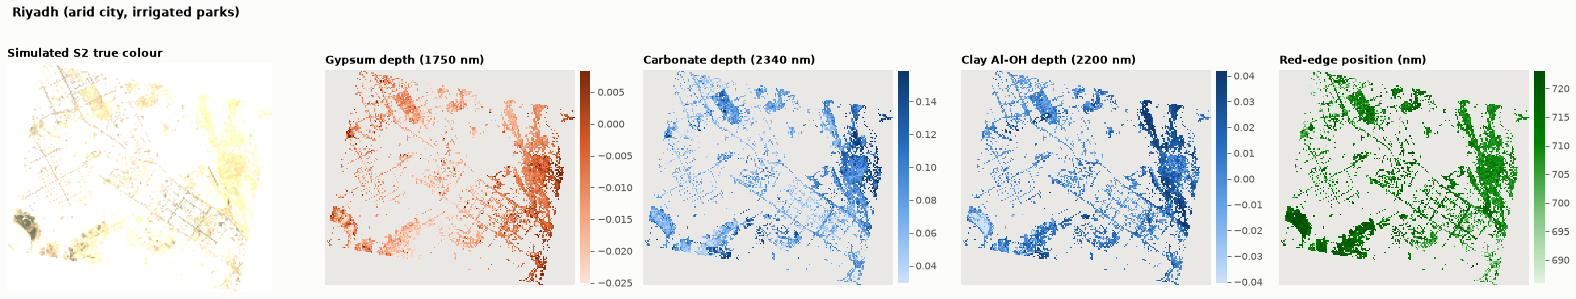

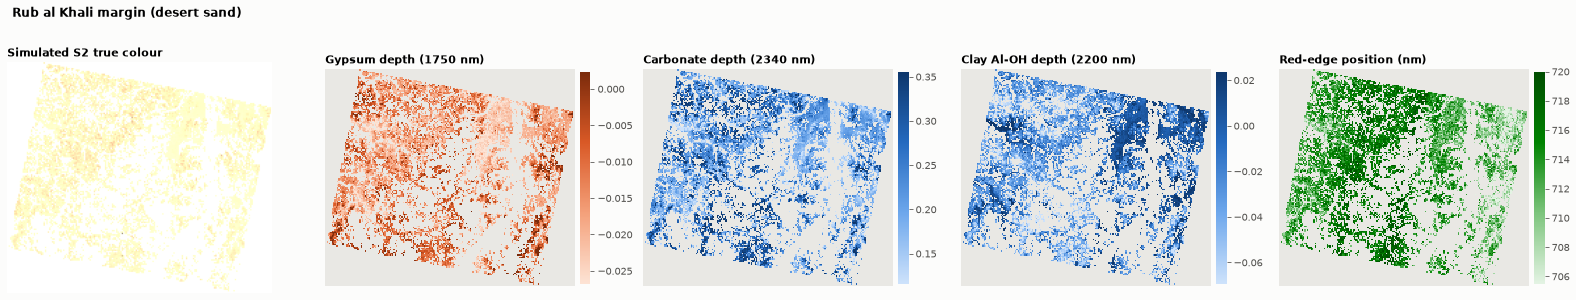

In [3]:
for sid, m in tmaps.items():
    land = m["land"].astype(bool)
    fig, ax = plt.subplots(1, 5, figsize=(22, 4.6))
    rgb = np.dstack([m["B04"], m["B03"], m["B02"]]).astype("float32")
    ax[0].imshow(np.clip(np.nan_to_num(rgb, nan=1) * 3.2, 0, 1)); ax[0].set_title("Simulated S2 true colour", loc="left"); ax[0].axis("off")
    specs = [("GYPSUM_1750", "Gypsum depth (1750 nm)", viz.SEQ_ORANGE), ("CARBONATE_2340", "Carbonate depth (2340 nm)", viz.SEQ_BLUE),
             ("CLAY_2200", "Clay Al-OH depth (2200 nm)", viz.SEQ_BLUE), ("REP", "Red-edge position (nm)", viz.SEQ_GREEN)]
    for a, (k, t, cm) in zip(ax[1:], specs):
        arr = m[k].astype("float32"); arr[~land] = np.nan
        v = arr[np.isfinite(arr)]
        viz._map(a, arr, t, cm, *(np.percentile(v, [2, 98]) if v.size else (0, 1)))
    fig.suptitle(tmeta[sid]["label"], x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); viz.save(fig, f"10_hs_features_{sid}.png"); plt.show()

## 2 · Hyperspectral soil-surface types and their spectra
Bare-ground pixels from all scenes are clustered on four narrow-band absorption depths (gypsum, clay, carbonate, 1200 nm water) that only a hyperspectral sensor resolves; mean spectra per class are reconstructed from the first scene's PCA basis.

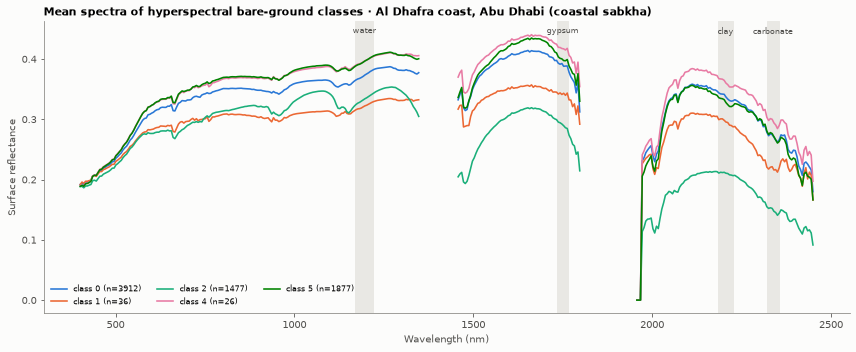

In [4]:
rec = hyperspectral.soil_class_recovery(tdf, k=6)
sid0 = next(iter(tmaps)); m0 = tmaps[sid0]
wl = m0["wavelengths"]; comps = m0["pca_components"]; mean = m0["pca_mean"]
pcs = [c for c in tdf.columns if c.startswith("PC")]
sub = tdf.loc[rec["index"]]
fig, ax = plt.subplots(figsize=(12, 5))
for k in range(rec["k"]):
    sel = rec["labels"] == k
    # PCA bases differ per scene; reconstruct only with this scene's basis
    s = sub[sel & (sub["scene"] == sid0).to_numpy()]
    if len(s) < 20: continue
    spec = s[pcs].to_numpy().mean(0) @ comps + mean
    gaps = np.r_[False, np.diff(wl) > 20]
    y = spec.copy(); y[gaps] = np.nan
    ax.plot(wl, y, color=viz.CAT[k], lw=1.6, label=f"class {k} (n={len(s)})")
for lo_, hi_, name in [(1735, 1765, "gypsum"), (2185, 2225, "clay"), (2320, 2355, "carbonate"), (1170, 1220, "water")]:
    ax.axvspan(lo_, hi_, color="#e9e8e4", zorder=0); ax.text((lo_+hi_)/2, ax.get_ylim()[1]*0.98, name, ha="center", va="top", fontsize=8, color=viz.INK2)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Surface reflectance"); ax.legend(ncol=3, fontsize=8)
ax.set_title(f"Mean spectra of hyperspectral bare-ground classes · {tmeta[sid0]['label']}", loc="left")
fig.tight_layout(); viz.save(fig, "11_hs_soil_spectra.png"); plt.show()

## 3 · Can Sentinel-2 see the same thing? (spatially-blocked cross-validation)

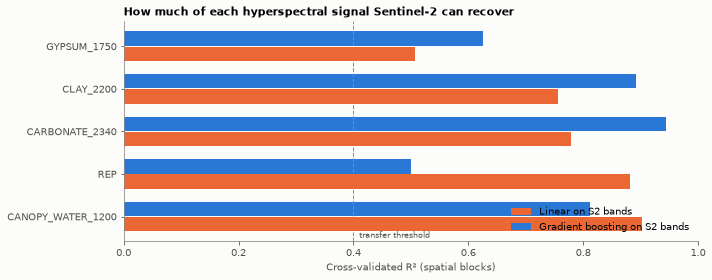

,target,pixels,n,r2_linear,r2_boosted,mae_boosted,hyperspectral_only_info_pct
0,GYPSUM_1750,soil,30872,0.507,0.625,0.005,37.510
1,CLAY_2200,soil,30872,0.756,0.892,0.007,10.831
2,CARBONATE_2340,soil,30872,0.779,0.944,0.016,5.596
3,REP,veg,276,0.882,0.500,0.667,50.033
4,CANOPY_WATER_1200,veg,276,0.902,0.811,0.007,18.865


In [5]:
cv = hyperspectral.evaluate_transfer(tdf)
cv.to_csv(config.RESULTS_DIR / "hyperspectral_transfer_cv.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(cv))
ax.barh(y + 0.18, cv["r2_linear"].clip(lower=0), height=0.34, color=viz.CAT[1], label="Linear on S2 bands")
ax.barh(y - 0.18, cv["r2_boosted"].clip(lower=0), height=0.34, color=viz.CAT[0], label="Gradient boosting on S2 bands")
ax.set_yticks(y, cv["target"]); ax.set_xlim(0, 1); ax.axvline(0.4, color=viz.MUTED, ls="--", lw=1)
ax.text(0.41, len(cv) - 0.5, "transfer threshold", fontsize=8, color=viz.INK2)
ax.set_xlabel("Cross-validated R² (spatial blocks)"); ax.legend(loc="lower right"); ax.invert_yaxis()
ax.set_title("How much of each hyperspectral signal Sentinel-2 can recover", loc="left")
fig.tight_layout(); viz.save(fig, "12_hs_transfer_r2.png"); plt.show()
cv.round(3)

Sentinel-2 recovers the 6 hyperspectral soil classes with balanced accuracy 0.82 (chance = 0.17)


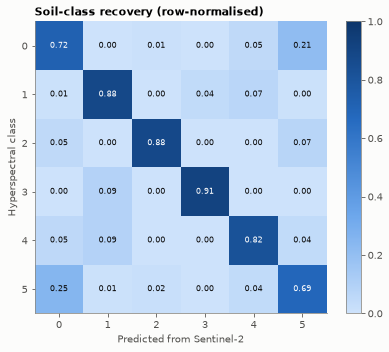

In [6]:
print(f"Sentinel-2 recovers the {rec['k']} hyperspectral soil classes with balanced accuracy "
      f"{rec['balanced_accuracy']:.2f} (chance = {rec['chance']:.2f})")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(rec["confusion"].to_numpy(), cmap=viz.SEQ_BLUE, vmin=0, vmax=1)
ax.set_xlabel("Predicted from Sentinel-2"); ax.set_ylabel("Hyperspectral class")
ax.set_xticks(range(rec["k"])); ax.set_yticks(range(rec["k"]))
for i in range(rec["k"]):
    for j in range(rec["k"]):
        v = rec["confusion"].to_numpy()[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.5 else viz.INK)
plt.colorbar(im, ax=ax, fraction=0.04); ax.set_title("Soil-class recovery (row-normalised)", loc="left")
fig.tight_layout(); viz.save(fig, "13_hs_soil_confusion.png"); plt.show()
json.dump({"soil_class_balanced_accuracy": rec["balanced_accuracy"], "chance": rec["chance"], "k": rec["k"]},
          open(config.RESULTS_DIR / "hyperspectral_soil_recovery.json", "w"), indent=2)

## 4 · What this means for Ecoverse
- Targets with **high R²** can be approximated from free Sentinel-2 everywhere in Bahrain today; the main notebook transfers them.
- Targets with **low R²** (the "hyperspectral-only information" column) and soil classes Sentinel-2 confuses are precisely the
  measurements that justify **Satellite 813**: they decide between, e.g., a gypsum-rich sabkha crust (where only halophytes like
  *Suaeda*, *Arthrocnemum* or *Salvadora* survive) and a bright but non-saline sand (where *Haloxylon* or *Pennisetum* are cheaper).
- Caveats: two analogue scenes; Tanager-simulated Sentinel-2 is not identical to real Sentinel-2 L2A reflectance; no field spectra.